## 原教材章末习题：第1—10题逐题整理



**范围、编号与使用方法**

本部分对应你提供的Python版教材第63—67页（原PDF第73—77页）的2.4全部10道题，保留原题号与(a)、(b)等小问对应关系。题干以中文概括，答案为本书编写的参考解答，不是作者官方答案。此前练习2.1—2.49及Auto建模项目保留；这里使用“教材第几题”，避免把两套编号混为一谈。

概念题先回答再说明理由，应用题先说明操作目的，再给出小代码块、真实输出与解释。第8—10题是探索性分析，不把全数据探索包装成独立测试成绩。所有图形由配套Notebook生成；第3题特别标明是构造的示意曲线。

## 教材第1题：何时需要更灵活的方法？


**题目要点（对应原题各小问）**
分别讨论：(a)样本数$n$很大、特征数$p$很小；(b)$p$很大、$n$很小；(c)真实输入输出关系高度非线性；(d)误差项方差很大。更灵活的方法通常更好还是更差？说明原因。

**参考答案**
**(a)通常更有利。**大量样本有助于稳定估计，少量特征减轻空间稀疏问题；若简单方法有明显近似偏差，提高灵活性可能降低测试误差。但若真实关系本来很简单，复杂方法不保证更好。

**(b)通常更不利。**高维、小样本时，很多复杂关系都能解释训练数据，估计容易随样本波动；更灵活的方法常以更高方差为代价。约束、正则化或合理降低维度可能有帮助。

**(c)通常更有利。**简单模型类可能无法表示真实弯曲关系，灵活模型可减小近似偏差；仍需要足够数据控制方差。

**(d)通常更不利。**噪声很大时，额外灵活性更容易追随随机扰动，降低训练误差却增大估计方差；更简单的方法可能更稳定。不可约误差本身不会因增加灵活性而消失。

四项都是典型趋势，不是对所有算法与数据都成立的保证。最终比较同一目标分布下的验证表现，并结合业务代价。

## 教材第2题：识别任务、目标与样本结构


**题目要点（对应原题各小问）**
(a)500家公司记录利润、员工数、行业及CEO薪资，研究薪资与哪些因素有关。(b)20个历史产品记录成败、价格、营销预算、竞品价格及另外10项变量，预测新产品成败。(c)按2012年每周的美、英、德股市涨跌幅，预测美元/欧元汇率的百分比变化。分别说明回归或分类、推断或预测，以及$n,p$。

**参考答案**
**(a)**回归，主要目标为推断（inference）；$Y$是薪资，$X$为利润、员工数和行业，$n=500,p=3$。这里$p$数原始预测变量；行业做独热编码后，设计矩阵列数可能多于3。观察性关联不自动表示因果影响。

**(b)**二分类，主要目标为预测（prediction）；$Y$为成败，$n=20,p=3+10=13$。响应变量不计入$p$。样本相对特征很少，应特别注意过拟合，不能把20个样本上的高准确率当作稳健保证。

**(c)**回归，主要目标为预测；三个股市的变化是输入，所以$p=3$，按题目通常的一年52周约定，$n=52$。真实周频数据应以实际时间索引核对行数。若声称提前预测，还要明确这些输入在预测时是否已经可得，并按时间顺序验证；同期关联与提前预测是不同任务。

## 教材第3题：画出偏差、方差与误差曲线


**题目要点（对应原题各小问）**
(a)在同一张图中画出平方偏差、方差、训练误差、测试误差及不可约误差随灵活性的典型变化。(b)逐条解释曲线形状。

**参考答案**
固定输入$x$，在此前推导的假设下，期望平方测试误差为

$$R(x)=\operatorname{Bias}(x)^2+\operatorname{Var}(\hat f(x))+\sigma^2(x).$$

若对$X$取平均，同样可将三项分别平均。典型情形下：平方偏差随灵活性增加而下降；估计方差上升；训练误差下降；测试误差先因偏差降低而下降，再因方差增大而上升；不可约误差由数据生成过程决定，画为水平线。

训练误差下降的严格理由需要条件：若模型类嵌套且都求得同一训练损失的全局最小值，大模型类包含小模型类的全部候选，最小值便不可能更大。对于不嵌套的算法、优化失败或特定有限样本，不能保证以上每条曲线都单调或测试误差严格呈U形。

### 代码 2.4-17 准备章末实验目录与工具

在VS Code中打开本章目录，选择myenv内核，从Notebook第一块开始运行。相对路径均以“代码/第二章”为工作目录。数据、图片与结果分开保存，便于复现。

In [2]:
from pathlib import Path
from urllib.request import urlopen
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_dir = Path("数据")
image_dir = Path("图片")
result_dir = Path("结果/教材章末习题")
for folder in [data_dir, image_dir, result_dir]:
    folder.mkdir(parents=True, exist_ok=True)


### 代码 2.4-18 用明确公式构造五条示意曲线

这里把灵活性缩放到0至1。前三项分别构造为$5(1-t)^2$、$4t^2$、1，因此示意测试误差为$6-10t+9t^2$，导数$-10+18t$在$t=5/9$为零，二阶导数18为正。训练曲线另行构造；它恰与平方偏差曲线重合，只是本例的选择。为便于辨认，下一块将训练曲线改为$4.5(1-t)^2+0.1$。

In [3]:
flexibility = np.linspace(0, 1, 201)
bias_squared = 5 * (1 - flexibility) ** 2
variance = 4 * flexibility ** 2
irreducible = np.full_like(flexibility, 1.0)
test_error = bias_squared + variance + irreducible
training_error = 5 * (1 - flexibility) ** 2


### 代码 2.4-19 五条曲线的教学示意图

图中的英文依次表示平方偏差、方差、训练误差、测试误差、不可约误差。**这些是按公式构造的教学曲线，不是对真实数据训练所得的实验结果。**图只帮助解释典型权衡，不声称对所有模型成立。

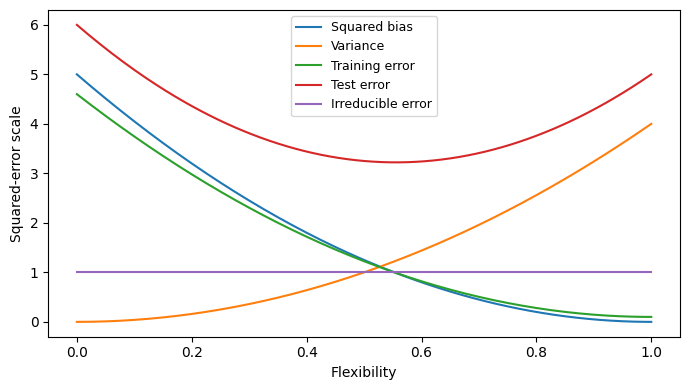

In [4]:
training_error = 4.5 * (1 - flexibility) ** 2 + 0.1
curves = {"Squared bias": bias_squared,
          "Variance": variance, "Training error": training_error,
          "Test error": test_error, "Irreducible error": irreducible}
fig, ax = plt.subplots(figsize=(7, 4))
for label, values in curves.items():
    ax.plot(flexibility, values, label=label)
ax.set(xlabel="Flexibility", ylabel="Squared-error scale")
ax.legend(fontsize=9)
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-curves.{suffix}", dpi=180)
display(fig)
plt.close(fig)


## 教材第4题：提出真实应用场景


**题目要点（对应原题各小问）**
(a)给出三个分类场景，说明响应、输入及推断/预测目标。(b)对回归给出三个场景并作同样说明。(c)给出三个聚类场景。开放题允许不同合理答案。

**参考答案**
**(a)分类。**①垃圾邮件过滤：$Y$为垃圾/正常，$X$为正文词频、链接数、发件历史，主要目标为预测；新邮件到来时立即决策。②设备故障预警：$Y$为未来24小时是否故障，$X$为当前温度、振动、运行时长，主要目标为预测；未来维修记录不可提前作为输入。③客户流失因素分析：$Y$为下月是否流失，$X$为本月使用频次、费用与投诉，主要目标为推断，研究条件关联；若要评价“降价会否减少流失”，还需因果研究设计。

**(b)回归。**①次日订单数预测：$Y$为数量，$X$为历史订单、星期、已知促销，主要目标为预测；整数响应仍可属于回归。②房租因素分析：$Y$为月租，$X$为面积、位置、楼龄，主要目标为推断；系数描述控制其他变量后的模型关联。③配送时长预测：$Y$为分钟数，$X$为距离、出发时间、当时可得路况，主要目标为预测，不能输入送达后才知道的变量。

**(c)聚类。**①按历史购买频率、客单价、品类偏好探索客户群；②按文章词向量探索文档主题；③按设备多传感器的运行特征探索工况。三者都没有预先给定的目标类别；聚类编号需要通过组内特征、稳定性与业务用途解释，不能直接称为真实类别。

## 教材第5题：灵活性的收益与代价


**题目要点（对应原题各小问）**
高度灵活的回归或分类方法有哪些优缺点？何时更倾向灵活方法，何时更倾向简单方法？

**参考答案**
灵活方法能描述复杂的非线性、交互与不规则边界，降低模型类过于简单造成的偏差。代价可能是估计方差更大、数据需求更高、调参更复杂、解释与维护更困难；计算代价是否更高要看具体算法，不能一概而论。

当真实关系复杂、有足够代表性数据、主要追求预测且验证收益稳定时，可优先考虑灵活方法。样本小、噪声大、关系近似简单，或业务强调可解释性、稳定性与资源限制时，可优先考虑简单方法。选择依据是泛化与业务效益，不是训练拟合程度。模型灵活性与可解释性常有权衡，但不是完全等价的单一刻度。

## 教材第6题：参数方法与非参数方法


**题目要点（对应原题各小问）**
两类方法如何区别？与非参数方法相比，参数方法在回归或分类中的优势与局限是什么？

**参考答案**
参数方法先给出由有限维参数描述的模型形式，再从数据估计参数。例如固定$p$的线性回归$f_\beta(x)=\beta_0+\sum_{j=1}^p\beta_jx_j$，未知量为$p+1$个系数；样本增加改变估计值，不改变这个设定下的参数个数。

非参数方法不把未知函数限制为一个预先固定维数的参数族。例如KNN保留训练样本，通过局部邻居给出预测，其表示复杂度可随数据增加。**“非参数”不等于没有任何参数或超参数**，KNN仍有$K$和距离选择。

参数方法的结构约束使估计通常更简洁，数据需求可能较低，某些模型的系数易于解释，也便于推断。若模型形式错误，更多数据也未必能消除近似偏差。非参数方法更能适应复杂关系，但常需要更多数据；高维下邻域稀疏、方差与调参问题更突出。参数模型也可很灵活，两种分类维度不能混为一谈。

## 教材第7题：手算并验证KNN分类


**题目要点（对应原题各小问）**
六条样本的$(X_1,X_2,X_3;Y)$为$(0,3,0;\mathrm{Red})$、$(2,0,0;\mathrm{Red})$、$(0,1,3;\mathrm{Red})$、$(0,1,2;\mathrm{Green})$、$(-1,0,1;\mathrm{Green})$、$(1,1,1;\mathrm{Red})$。对原点预测：(a)算各距离；(b)求$K=1$结果；(c)求$K=3$结果；(d)高度非线性的贝叶斯边界通常需要较大还是较小的$K$？

**参考答案**
**(a)**欧氏距离为$d_i=\sqrt{(x_{i1}-0)^2+(x_{i2}-0)^2+(x_{i3}-0)^2}$，按原行序得到

$$3,\quad2,\quad\sqrt{10},\quad\sqrt5,\quad\sqrt2,\quad\sqrt3.$$

例如第5行是$\sqrt{(-1)^2+0^2+1^2}=\sqrt2$，距离不会因为坐标为负而成为负数。由近到远为第5、6、2、4、1、3行。

**(b)**$K=1$只看第5行，预测Green。**(c)**$K=3$看第5、6、2行，标签Green、Red、Red，红色占$2/3$，预测Red。这是邻域经验比例，不是真实条件概率的已知值。

**(d)**较小的$K$对应较局部、较灵活的边界，因此在高度非线性情况下通常更有机会降低偏差；但太小会增加方差，不能由“非线性”直接推出$K=1$最优。应利用验证数据选择。

### 代码 2.4-20 计算每个样本到原点的距离

平方后按axis=1沿每一行求和，得到每条样本的平方距离。argsort返回从小到大排列的行位置；打印时加1，才与题目从1开始的样本编号对应。

In [5]:
X_knn = np.array([[0, 3, 0], [2, 0, 0], [0, 1, 3],
                  [0, 1, 2], [-1, 0, 1], [1, 1, 1]])
y_knn = np.array(["Red", "Red", "Red", "Green", "Green", "Red"])
distance = np.sqrt(np.sum(X_knn ** 2, axis=1))
order = np.argsort(distance)
print("distances:", np.round(distance, 4))
print("nearest observation numbers:", order + 1)


distances: [3.     2.     3.1623 2.2361 1.4142 1.7321]
nearest observation numbers: [5 6 2 4 1 3]


### 代码 2.4-21 分别检查一个与三个邻居的投票

先用最近邻位置取标签，再计数，最后选频数最高的类别。本题没有投票并列；一般程序若遇到并列，需要预先规定处理规则。

In [6]:
for k in [1, 3]:
    neighbor_labels = y_knn[order[:k]]
    counts = pd.Series(neighbor_labels).value_counts()
    print("K =", k, "neighbors:", neighbor_labels.tolist())
    print("prediction:", counts.idxmax())


K = 1 neighbors: ['Green']
prediction: Green
K = 3 neighbors: ['Green', 'Red', 'Red']
prediction: Red


## 教材第8题：College：从索引到探索性分析


**题目要点（对应原题各小问）**
(a)读取College.csv；(b)检查学校名称列，并分别用index_col或rename/set_index设置索引；(c)数值摘要；(d)Top10perc、Apps、Enroll散点矩阵；(e)按Private画Outstate箱线图；(f)按Top10perc是否超过50定义Elite、计数并画箱线图；(g)不同分箱数的直方图；(h)继续探索并总结。

**参考答案**
这组练习关心777所学校的表结构与分布，不训练预测模型。先保留学校名称作为行索引，再分析变量。Private为公私立类别；Apps、Accept、Enroll分别为申请、录取、入学人数；Top10perc与Top25perc为新生高中成绩排名百分比。其余字段含全日制/非全日制学生数、学费、生活费用、教师学位比例、师生比、校友捐赠比例、每生支出和毕业率。下面按(a)—(h)给出可运行解答。

### 代码 2.4-22 第8(a)：读取含学校名称的官方CSV

先查看前三行的前四列，确认第一列确实是学校名称。教材官网下载的文件包含名称列，ISLP包内另一个版本可能不含名称；不能把数值第一列Private误设为学校索引。完整DataFrame可在VS Code变量查看器中查看。

In [7]:
college_path = data_dir / "College.csv"
college_url = "https://www.statlearning.com/s/College.csv"
if not college_path.exists():
    college_path.write_bytes(urlopen(college_url, timeout=30).read())
college_raw = pd.read_csv(college_path)
print("raw shape:", college_raw.shape)
print(college_raw.iloc[:3, :4].to_string(index=False))


raw shape: (777, 19)
                  Unnamed: 0 Private  Apps  Accept
Abilene Christian University     Yes  1660    1232
          Adelphi University     Yes  2186    1924
              Adrian College     Yes  1428    1097


### 代码 2.4-23 第8(b)：用两种方法设置学校索引

rename中的字典表示“旧列名映射到新列名”；set_index将该列用于标识行，默认从普通数据列移除。equals核对两种方法的单元格结果一致；索引名称这种元信息可不同。

In [8]:
college2 = pd.read_csv(college_path, index_col=0)
college3 = college_raw.rename(columns={college_raw.columns[0]: "College"})
college3 = college3.set_index("College")
assert college2.equals(college3)
college = college3.copy()
print("shape:", college.shape)
print("unique school names:", college.index.is_unique)
print("first columns:", college.columns[:4].tolist())


shape: (777, 18)
unique school names: True
first columns: ['Private', 'Apps', 'Accept', 'Enroll']


### 代码 2.4-24 第8(c)：全部数值变量的基本摘要

describe默认汇总数值列，转置后每一行对应一个变量。std是分母$n-1$的样本标准差。Private是类别，另用value_counts计数；不能因为没有出现在数值摘要里就忽略它。

In [9]:
college_summary = college.describe().T
college_summary.to_csv(result_dir / "college_describe.csv")
basic_stats = ["count", "mean", "std", "min", "max"]
print(college_summary[basic_stats].round(2).to_string())
print("Private counts:", college["Private"].value_counts().to_dict())


             count      mean      std     min      max
Apps         777.0   3001.64  3870.20    81.0  48094.0
Accept       777.0   2018.80  2451.11    72.0  26330.0
Enroll       777.0    779.97   929.18    35.0   6392.0
Top10perc    777.0     27.56    17.64     1.0     96.0
Top25perc    777.0     55.80    19.80     9.0    100.0
F.Undergrad  777.0   3699.91  4850.42   139.0  31643.0
P.Undergrad  777.0    855.30  1522.43     1.0  21836.0
Outstate     777.0  10440.67  4023.02  2340.0  21700.0
Room.Board   777.0   4357.53  1096.70  1780.0   8124.0
Books        777.0    549.38   165.11    96.0   2340.0
Personal     777.0   1340.64   677.07   250.0   6800.0
PhD          777.0     72.66    16.33     8.0    103.0
Terminal     777.0     79.70    14.72    24.0    100.0
S.F.Ratio    777.0     14.09     3.96     2.5     39.8
perc.alumni  777.0     22.74    12.39     0.0     64.0
Expend       777.0   9660.17  5221.77  3186.0  56233.0
Grad.Rate    777.0     65.46    17.18    10.0    118.0
Private co

### 代码 2.4-25 第8(c)：补齐四分位数摘要

25%、50%、75%分别是第一四分位数、中位数与第三四分位数。两块输出合起来完整展示describe结果；CSV保留全部精度，PDF显示两位小数。

In [10]:
quantiles = ["25%", "50%", "75%"]
print(college_summary[quantiles].round(2).to_string())


                25%     50%      75%
Apps          776.0  1558.0   3624.0
Accept        604.0  1110.0   2424.0
Enroll        242.0   434.0    902.0
Top10perc      15.0    23.0     35.0
Top25perc      41.0    54.0     69.0
F.Undergrad   992.0  1707.0   4005.0
P.Undergrad    95.0   353.0    967.0
Outstate     7320.0  9990.0  12925.0
Room.Board   3597.0  4200.0   5050.0
Books         470.0   500.0    600.0
Personal      850.0  1200.0   1700.0
PhD            62.0    75.0     85.0
Terminal       71.0    82.0     92.0
S.F.Ratio      11.5    13.6     16.5
perc.alumni    13.0    21.0     31.0
Expend       6751.0  8377.0  10830.0
Grad.Rate      53.0    65.0     78.0

### 代码 2.4-26 第8(d)：三个变量的散点矩阵

对角线显示单变量直方图，非对角线显示两变量关系。重点观察Apps与Enroll的共同增长、学校规模差异与右尾；Top10perc与规模的关系不能只凭一条直线概括。图形关联不代表多发申请就会造成某所学校扩招。

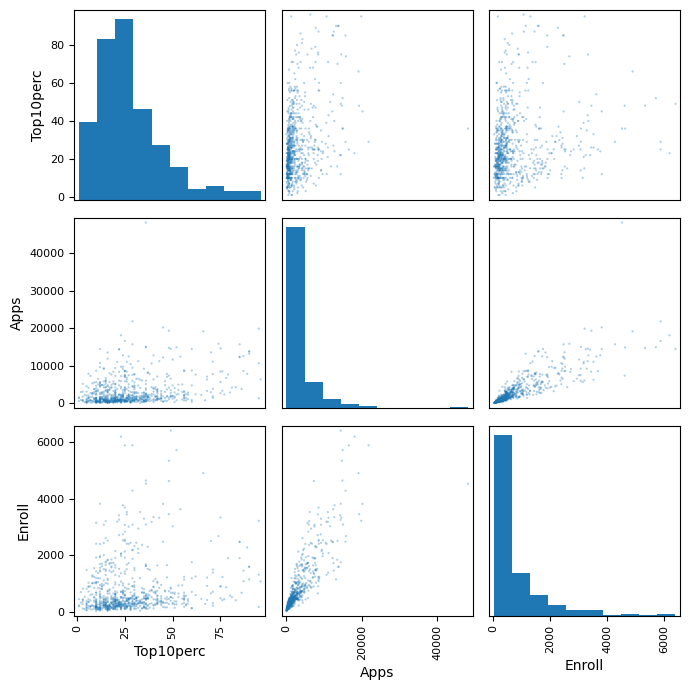

In [11]:
columns = ["Top10perc", "Apps", "Enroll"]
axes = pd.plotting.scatter_matrix(college[columns], figsize=(7, 7),
                                  alpha=0.35, diagonal="hist", s=10)
fig = axes[0, 0].figure
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-college-matrix.{suffix}", dpi=180)
display(fig)
plt.close(fig)


### 代码 2.4-27 第8(e)：公私立学校的州外学费

箱体表示中间50%的数据，单独标出的点不自动是错误。结合中位数表比较组间位置与组内离散程度，不能把组间差异解释为私立身份本身的因果效果。

         count   median
Private                
No         212   6609.0
Yes        565  11200.0


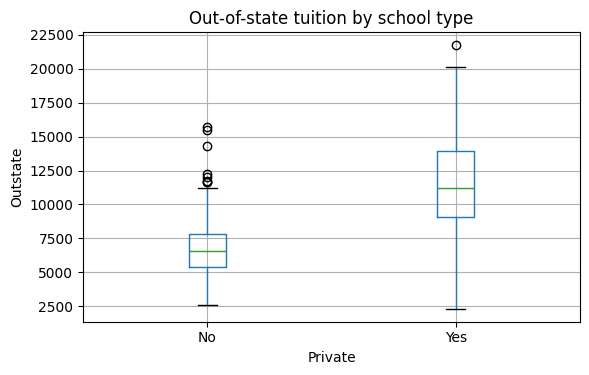

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
college.boxplot(column="Outstate", by="Private", ax=ax)
fig.suptitle("")
ax.set(title="Out-of-state tuition by school type", ylabel="Outstate")
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-college-private.{suffix}", dpi=180)
print(college.groupby("Private")["Outstate"].agg(["count", "median"]))
display(fig)
plt.close(fig)


**第8(f)：先核对百分数单位**

你提供的教材示例把Top10perc按$[0,0.5,1]$分箱，但这份CSV用1至96这样的百分数表示；50%应与50比较。这里用$[0,50,100]$并包含最低端点，得到“$\le50$为No、$>50$为Yes”。Elite只是本题定义的分组名称，不是大学综合质量的评价。

### 代码 2.4-28 第8(f)：构造Elite并核对边界

pd.cut默认区间右端闭合，因此50属于No。第二条断言用直接布尔比较核对分箱结果，防止比例单位或区间边界造成无声错误。

In [13]:
college["Elite"] = pd.cut(college["Top10perc"], bins=[0, 50, 100],
                          labels=["No", "Yes"], include_lowest=True)
assert college["Elite"].notna().all()
assert (college["Elite"] == "Yes").equals(college["Top10perc"] > 50)
print(college["Elite"].value_counts().to_string())


Elite
No     699
Yes     78


### 代码 2.4-29 第8(f)：按Elite比较州外学费

这里比较按入学成绩组成定义的两组学校的学费分布。observed=True仅汇总实际出现的类别；中位数不能表达整组所有学校，更不能建立因果关系。

Elite
No      9556.0
Yes    16950.0
Name: Outstate, dtype: float64


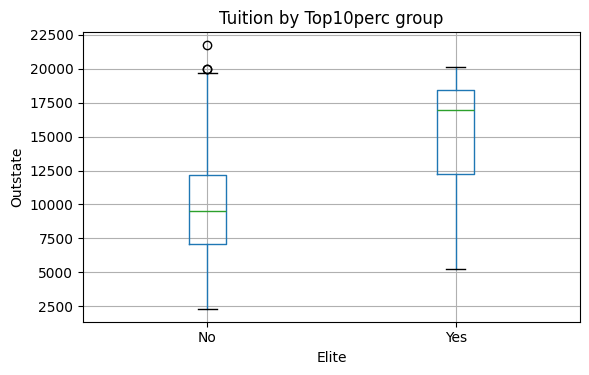

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
college.boxplot(column="Outstate", by="Elite", ax=ax)
fig.suptitle("")
ax.set(title="Tuition by Top10perc group", ylabel="Outstate")
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-college-elite.{suffix}", dpi=180)
print(college.groupby("Elite", observed=True)["Outstate"].median())
display(fig)
plt.close(fig)


### 代码 2.4-30 第8(g)：比较不同变量和分箱数

同一个Apps变量画10箱和30箱，才能直接看到分箱数如何改变细节；另两图观察学费与教学支出。分箱改变图形的平滑程度，不改变原始观测，也不改变样本总数。

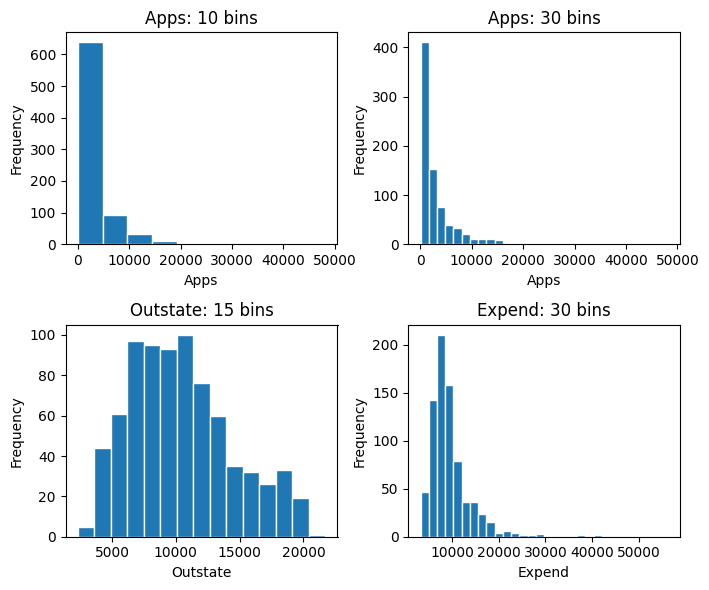

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(7, 6))
settings = [("Apps", 10), ("Apps", 30), ("Outstate", 15), ("Expend", 30)]
for ax, (column, bins) in zip(axes.flat, settings):
    college[column].plot.hist(bins=bins, ax=ax, edgecolor="white")
    ax.set(title=f"{column}: {bins} bins", xlabel=column)
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-college-hist.{suffix}", dpi=180)
display(fig)
plt.close(fig)


### 代码 2.4-31 第8(h)：检查偏态、相关与可疑毕业率

用均值与中位数配合直方图判断右偏；相关系数只概括线性关联。发现毕业率超过100时，先标记并追溯数据定义或录入来源。本练习不擅自删除或截断，统计结果保持与原文件一致。

In [16]:
print(college[["Apps", "Expend"]].agg(["mean", "median"]).round(2))
print("Apps-Enroll correlation:", round(college["Apps"].corr(college["Enroll"]), 4))
unusual = college.loc[college["Grad.Rate"] > 100, ["Grad.Rate"]]
print("Graduation rate above 100:")
print(unusual.to_string())


           Apps   Expend
mean    3001.64  9660.17
median  1558.00  8377.00
Apps-Enroll correlation: 0.8468
Graduation rate above 100:
                   Grad.Rate
College                     
Cazenovia College        118


**参考答案**

第8(h)可形成这样的简短报告：申请数与教学支出具有明显右尾，少数大值拉高均值；申请与入学人数正相关，但招生比例并不恒定；公私立与Elite组的学费位置有差异，组内仍有分散。毕业率存在超过通常百分数上界的记录，需要核查。以上结论来自这份历史样本的探索，不能直接推广为当代所有学校的规律。

## 教材第9题：Auto：描述统计、位置删除与图形


**题目要点（对应原题各小问）**
移除缺失后：(a)区分定量与定性变量；(b)求定量变量范围；(c)求均值与标准差；(d)移除第10至85条观测后重算；(e)画图探索变量关系；(f)哪些变量可能有助于预测mpg？

**参考答案**
**(a)**mpg、displacement、horsepower、weight、acceleration是定量变量；cylinders为离散计数，year为年份，可按定量变量描述，也可能在建模中作为有序/类别变量处理。origin是地区类别编码，不能把代码间差值当成天然距离；name是车型名称。若以mpg为预测目标，它是响应，不再是输入特征；下面仍列出它的摘要，便于完整核对数据。

**(b)(c)**范围报告最小值和最大值，另外列出max-min便于理解“极差”。标准差统一使用ddof=1。**(d)**按清理后行顺序，从1开始的第10至85条共$85-10+1=76$条，对应位置切片$[9:85]$，剩$392-76=316$条。不要把标签9至84与行位置混同，也不要忘记切片右端不包含。

### 代码 2.4-32 第9(a)：读取并清理Auto全部字段

本题要求先去掉缺失行，然后按现有顺序分析完整数据。这里用的是全部字段的dropna；本文件缺失集中在horsepower，仍得到392条。保留原索引以便核对后面的删除位置。

In [17]:
auto_path = data_dir / "Auto.data"
if not auto_path.exists():
    auto_path.write_bytes(urlopen("https://www.statlearning.com/s/Auto.data",
                                  timeout=30).read())
auto_full = pd.read_csv(auto_path, sep=r"\s+", na_values="?").dropna().copy()
quantitative = ["mpg", "cylinders", "displacement", "horsepower",
                "weight", "acceleration", "year"]
print("complete rows:", len(auto_full))
print("origin codes:", sorted(auto_full["origin"].unique().tolist()))


complete rows: 392
origin codes: [1, 2, 3]


### 代码 2.4-33 第9(b)(c)：范围、均值与样本标准差

agg依次应用最小值、最大值、均值和样本标准差；转置后每行一个变量。最后一列span表示极差，与[min,max]这一取值区间是相关但不同的表达。

In [18]:
auto_stats = auto_full[quantitative].agg(["min", "max", "mean", "std"]).T
auto_stats["span"] = auto_stats["max"] - auto_stats["min"]
print(auto_stats.round(3).to_string())
auto_stats.to_csv(result_dir / "auto_full_summary.csv")


                 min     max      mean      std    span
mpg              9.0    46.6    23.446    7.805    37.6
cylinders        3.0     8.0     5.472    1.706     5.0
displacement    68.0   455.0   194.412  104.644   387.0
horsepower      46.0   230.0   104.469   38.491   184.0
weight        1613.0  5140.0  2977.584  849.403  3527.0
acceleration     8.0    24.8    15.541    2.759    16.8
year            70.0    82.0    75.980    3.684    12.0


### 代码 2.4-34 第9(d)：按行位置移除第10至85条

keep是与当前表等长的位置掩码；前9条保留、第10至85条移除、第86条起保留。这里是练习规定的删除，不是训练/验证划分，也不意味着可为了改善模型成绩任意删行。

In [19]:
keep = np.ones(len(auto_full), dtype=bool)
keep[9:85] = False
auto_subset = auto_full.iloc[keep].copy()
subset_stats = auto_subset[quantitative].agg(["min", "max", "mean", "std"]).T
subset_stats["span"] = subset_stats["max"] - subset_stats["min"]
print("removed:", (~keep).sum(), "remaining:", len(auto_subset))
print(subset_stats.round(3).to_string())
subset_stats.to_csv(result_dir / "auto_subset_summary.csv")


removed: 76 remaining: 316
                 min     max      mean      std    span
mpg             11.0    46.6    24.404    7.867    35.6
cylinders        3.0     8.0     5.373    1.654     5.0
displacement    68.0   455.0   187.241   99.678   387.0
horsepower      46.0   230.0   100.722   35.709   184.0
weight        1649.0  4997.0  2935.972  811.300  3348.0
acceleration     8.5    24.8    15.727    2.694    16.3
year            70.0    82.0    77.146    3.106    12.0


### 代码 2.4-35 第9(e)：探索几个预测变量的关系

这里恢复使用全部392条完整记录。观察排量、马力、重量之间的明显关联，说明多个输入可能携带重叠信息；加速时间与这些变量的关系更分散。相关输入会影响系数解释，不等于必须机械删除某一列。

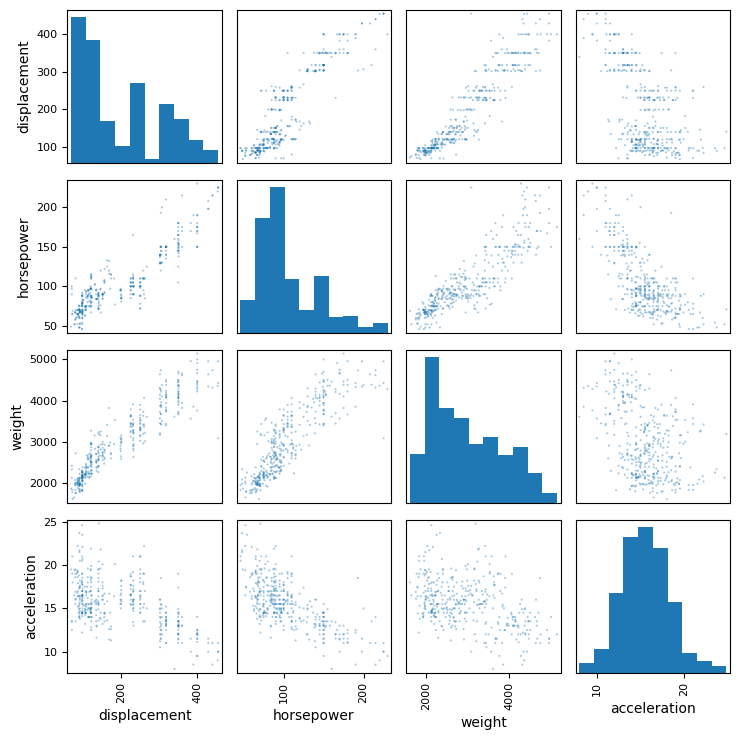

In [20]:
columns = ["displacement", "horsepower", "weight", "acceleration"]
axes = pd.plotting.scatter_matrix(auto_full[columns], figsize=(7.5, 7.5),
                                  alpha=0.4, s=9, diagonal="hist")
fig = axes[0, 0].figure
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-auto-matrix.{suffix}", dpi=180)
display(fig)
plt.close(fig)


### 代码 2.4-36 第9(f)：观察mpg与候选输入的关系

马力、重量、排量与mpg呈负关联，年份呈正关联，因此值得作为候选输入。origin分组也有差异，但它是类别。图形只提示可能的预测信息；是否提供额外价值，仍需在合理划分下比较验证误差。此处不把全样本的相关系数当作测试性能。

cylinders      -0.7776
displacement   -0.8051
horsepower     -0.7784
weight         -0.8322
acceleration    0.4233
year            0.5805
Name: mpg, dtype: float64


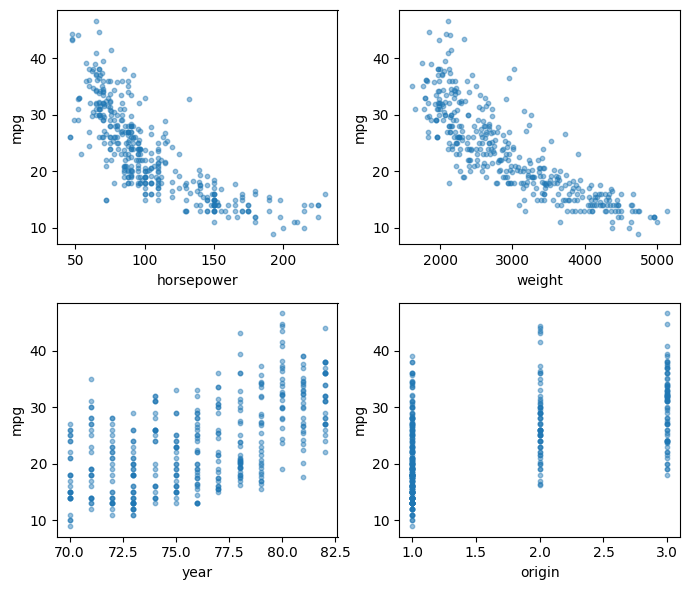

In [21]:
features = ["horsepower", "weight", "year", "origin"]
fig, axes = plt.subplots(2, 2, figsize=(7, 6))
for ax, feature in zip(axes.flat, features):
    ax.scatter(auto_full[feature], auto_full["mpg"], s=10, alpha=0.45)
    ax.set(xlabel=feature, ylabel="mpg")
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-auto-mpg.{suffix}", dpi=180)
print(auto_full[quantitative].corr()["mpg"].drop("mpg").round(4))
display(fig)
plt.close(fig)


## 教材第10题：Boston：分布、关联与条件筛选


**题目要点（对应原题各小问）**
(a)载入ISLP的Boston；(b)解释行列；(c)成对散点图；(d)哪些变量与crim关联；(e)检查高犯罪率、税率、师生比及变量范围；(f)临河地区数；(g)师生比中位数；(h)最低medv记录及其余变量相对总体的位置；(i)平均房间数超过7和8的地区数，并描述超过8的地区。

**参考答案**
使用Python版ISLP数据：506条地区记录、13列，不混用其他版本的14列数据。每行是一个地区汇总观测，不是一栋房屋或一个居民；文件没有可供本题确定地区实名的字段，因此只能报告行标签。crim为地区人均犯罪率，chas为是否临河，rm为每套住宅平均房间数，ptratio为师生比，medv为自有住房价格中位数（单位为千美元）。其他列依次描述住宅用地、非零售用地、污染、旧住宅比例、就业中心距离、公路可达性、税率和历史人口指标。

本题是历史数据的描述练习。地区汇总关联不能推出个体行为或因果机制。lstat是原数据使用的历史社会分类指标；在此仅按原字段解释与计算，不把该标签作为对居民价值的判断。

### 代码 2.4-37 第10(a)(b)：通过ISLP载入Boston

本机myenv已安装ISLP 0.4.1。其他电脑需先在Notebook所用内核安装ISLP；本题只调用其load_data接口。已保存加载结果供核对，并在数据目录保留同一官方数据的CSV副本。

In [22]:
from ISLP import load_data
import ISLP

boston = load_data("Boston")
print("ISLP version:", ISLP.__version__)
print("shape:", boston.shape)
print("columns:", boston.columns.tolist())
boston.to_csv(result_dir / "boston_loaded.csv", index=False)


ISLP version: 0.4.1
shape: (506, 13)
columns: ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv']


### 代码 2.4-38 第10(c)：查看部分变量的成对关系

可以观察nox与dis的负关联、rm与medv的正关联、lstat与medv的负关联及非线性形态。medv上端有一条水平堆积，提示需要核查数据记录口径；不能仅凭图形把它当成普通连续尾部。

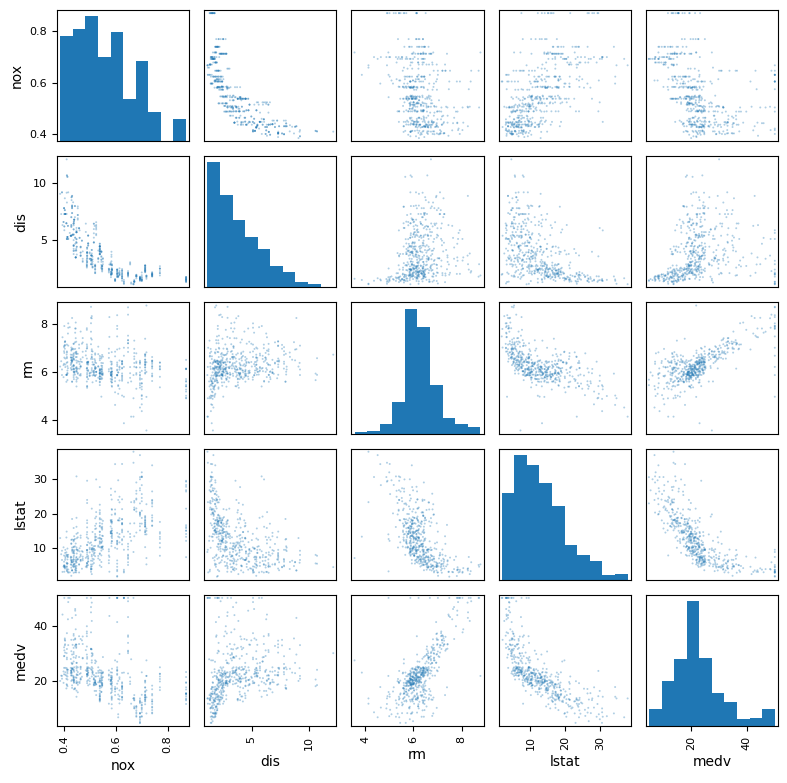

In [23]:
columns = ["nox", "dis", "rm", "lstat", "medv"]
axes = pd.plotting.scatter_matrix(boston[columns], figsize=(8, 8),
                                  alpha=0.35, s=8, diagonal="hist")
diagonal = axes[0, 0]
labels = [f"{float(t.get_text()):g}" for t in diagonal.get_yticklabels()]
diagonal.set_yticks(diagonal.get_yticks(), labels=labels)
fig = axes[0, 0].figure
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-boston-matrix.{suffix}", dpi=180)
display(fig)
plt.close(fig)


### 代码 2.4-39 第10(d)：犯罪率关联的数值摘要

Pearson相关系数概括线性关联；绝对值小不等于没有非线性关系，大也不等于因果作用。关注rad、tax、lstat、nox的正关联与medv、dis的负关联，同时用图形检查离群与偏态的影响。

In [24]:
crime_corr = boston.corr(numeric_only=True)["crim"].drop("crim")
print(crime_corr.sort_values().round(4).to_string())
crime_corr.to_csv(result_dir / "boston_crime_correlations.csv")


medv      -0.3883
dis       -0.3797
rm        -0.2192
zn        -0.2005
chas      -0.0559
ptratio    0.2899
age        0.3527
indus      0.4066
nox        0.4210
lstat      0.4556
tax        0.5828
rad        0.6255


### 代码 2.4-40 第10(d)：用散点图核对犯罪率关联

图中的竖直带反映rad、tax的取值集中，少数高crim点可能明显影响相关系数。不要把“高税率地区犯罪率高”转换为“提高税率会提高犯罪率”。

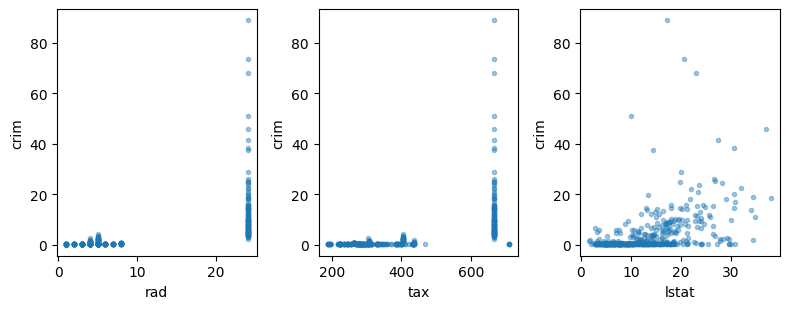

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(8, 3.2))
for ax, feature in zip(axes, ["rad", "tax", "lstat"]):
    ax.scatter(boston[feature], boston["crim"], s=9, alpha=0.4)
    ax.set(xlabel=feature, ylabel="crim")
fig.tight_layout()
for suffix in ["pdf", "png"]:
    fig.savefig(image_dir / f"241-boston-crime.{suffix}", dpi=180)
display(fig)
plt.close(fig)


### 代码 2.4-41 第10(e)：每个变量的范围与中位数

先报告全部变量的范围，避免只选择支持印象的几列；中位数提供典型水平，帮助判断最大值到底有多极端。chas虽用0/1保存，语义仍是类别。

In [26]:
boston_ranges = boston.agg(["min", "median", "max"]).T
print(boston_ranges.round(4).to_string())
boston_ranges.to_csv(result_dir / "boston_ranges.csv")


              min    median       max
crim       0.0063    0.2565   88.9762
zn         0.0000    0.0000  100.0000
indus      0.4600    9.6900   27.7400
chas       0.0000    0.0000    1.0000
nox        0.3850    0.5380    0.8710
rm         3.5610    6.2085    8.7800
age        2.9000   77.5000  100.0000
dis        1.1296    3.2074   12.1265
rad        1.0000    5.0000   24.0000
tax      187.0000  330.0000  711.0000
ptratio   12.6000   19.0500   22.0000
lstat      1.7300   11.3600   37.9700
medv       5.0000   21.2000   50.0000


### 代码 2.4-42 第10(e)：查看高犯罪率、税率与师生比记录

这里的“高”先用排序作描述，没有任意宣称超过某个阈值就异常。与上一表比较：crim最大值远高于中位数，右尾突出；tax与ptratio也有较高记录，但量纲与取值集中方式不同，不能直接比较数字大小。

In [27]:
for column in ["crim", "tax", "ptratio"]:
    largest = boston.nlargest(3, column)[[column]]
    print("Top 3 by", column)
    print(largest.to_string())


Top 3 by crim
        crim
380  88.9762
418  73.5341
405  67.9208
Top 3 by tax
     tax
488  711
489  711
490  711
Top 3 by ptratio
     ptratio
354     22.0
355     22.0
127     21.2


### 代码 2.4-43 第10(f)(g)：临河计数与师生比中位数

布尔值True求和相当于计数。ptratio中位数表示一半地区不高于它、一半不低于它；不是对所有学生加权后的全市师生比。

In [28]:
river_count = int((boston["chas"] == 1).sum())
ratio_median = boston["ptratio"].median()
print("river-bordering areas:", river_count)
print("median pupil-teacher ratio:", ratio_median)


river-bordering areas: 35
median pupil-teacher ratio: 19.05


### 代码 2.4-44 第10(h)：保留所有最低房价并列记录

不用idxmin只取第一行，因为最低medv可能并列。把每条最低记录与总体最小值、中位数和最大值逐项并排，才能回答“其余变量处在什么位置”。行标签不能解释为地名。

In [29]:
lowest = boston.loc[boston["medv"] == boston["medv"].min()]
print("zero-based row labels:", lowest.index.tolist())
print("one-based observation numbers:", (lowest.index + 1).tolist())
comparison = boston.agg(["min", "median", "max"]).T
for index, row in lowest.iterrows():
    comparison[f"row_{index}"] = row
print(comparison.round(3).to_string())
comparison.to_csv(result_dir / "boston_min_medv_comparison.csv")


zero-based row labels: [398, 405]
one-based observation numbers: [399, 406]
             min   median      max  row_398  row_405
crim       0.006    0.257   88.976   38.352   67.921
zn         0.000    0.000  100.000    0.000    0.000
indus      0.460    9.690   27.740   18.100   18.100
chas       0.000    0.000    1.000    0.000    0.000
nox        0.385    0.538    0.871    0.693    0.693
rm         3.561    6.208    8.780    5.453    5.683
age        2.900   77.500  100.000  100.000  100.000
dis        1.130    3.207   12.126    1.490    1.425
rad        1.000    5.000   24.000   24.000   24.000
tax      187.000  330.000  711.000  666.000  666.000
ptratio   12.600   19.050   22.000   20.200   20.200
lstat      1.730   11.360   37.970   30.590   22.980
medv       5.000   21.200   50.000    5.000    5.000


### 代码 2.4-45 第10(i)：筛选平均房间数较多的地区

条件是严格大于，rm=7或8不计入相应组。rm是地区内每套住宅房间数的平均值，不代表该地区每栋房屋都超过8间。表中通常较高的房价仍有明显例外，应保留这些例外来限定结论。

In [30]:
over7 = boston.loc[boston["rm"] > 7]
over8 = boston.loc[boston["rm"] > 8]
print("rm > 7:", len(over7), "rm > 8:", len(over8))
print(over8[["rm", "medv", "crim", "ptratio", "lstat"]].round(3).to_string())
summary8 = over8.agg(["min", "mean", "max"]).T
summary8.to_csv(result_dir / "boston_over8_summary.csv")


rm > 7: 64 rm > 8: 13
        rm  medv   crim  ptratio  lstat
97   8.069  38.7  0.121     18.0   4.21
163  8.375  50.0  1.519     14.7   3.32
204  8.034  50.0  0.020     14.7   2.88
224  8.266  44.8  0.315     17.4   4.14
225  8.725  50.0  0.527     17.4   4.63
226  8.040  37.6  0.382     17.4   3.13
232  8.337  41.7  0.575     17.4   2.47
233  8.247  48.3  0.331     17.4   3.95
253  8.259  42.8  0.369     19.1   3.54
257  8.704  50.0  0.612     13.0   5.12
262  8.398  48.8  0.520     13.0   5.91
267  8.297  50.0  0.578     13.0   7.44
364  8.780  21.9  3.474     20.2   5.29


**参考答案**

**第10(f)(g)**临河地区35个，师生比中位数19.05。

**第10(h)**最低medv为5（千美元），有两条并列记录：从0开始的行标签398、405，即第399、406条。两者crim分别约38.352和67.921，均远高于总体中位数0.257；nox为0.693，高于中位数0.538；rm分别5.453、5.683，低于中位数6.2085。age均为100，达到样本最大值；dis约1.490和1.425，接近较低端；rad均为24，达到最大值；tax均为666，接近上端711；ptratio均为20.2，高于中位数19.05。lstat分别30.59和22.98，高于中位数11.36；zn均为0，chas均为0，indus均为18.1。不能凭这些关联确定房价较低的因果原因。

**第10(i)**rm大于7的地区64个，大于8的13个。后者medv均值44.2、范围21.9至50；lstat均值4.31、ptratio均值约16.36。多数记录房价较高，但行364的rm最高（8.780），medv却只有21.9，说明房间数不能单独决定房价。完整13列的分组摘要已保存在CSV中。


**数据与复现来源**

College和Auto来自[教材Python资源页](https://www.statlearning.com/resources-python)；Boston通过ISLP 0.4.1载入，并与官方CSV核对一致。数据说明可查[College说明](https://intro-stat-learning.github.io/ISLP/datasets/College.html)与[Boston说明](https://intro-stat-learning.github.io/ISLP/datasets/Boston.html)。配套包保存数据校验值、软件版本及本次运行记录。若在其他电脑运行，请在所选Jupyter内核安装ISLP及NumPy、pandas、Matplotlib、scikit-learn。


**章末练习总结**

本组题把概念判断、手算、索引、描述统计、图形解读与可复现代码串在一起。概念题中的“通常”需要条件；应用题中的“相关”不等于因果或已验证的预测能力；题目给出的代码也需要核对单位与边界。下一章将进一步解释线性回归如何估计系数、如何量化不确定性，以及怎样诊断模型假设。

数据来源：College与Auto来自 https://www.statlearning.com/resources-python ，Boston来自ISLP 0.4.1。完整数据摘要保存在结果/教材章末习题。本Notebook对应原教材第1—10题，不是官方解答。